# Batch correction with Harmony

`epi.tl.harmony` is a pure-Python port of the R **harmony** package (Korsunsky *et al.*, *Nat Methods* 2019), in the exact form ArchR runs it:

```r
set.seed(1)
proj <- addHarmony(proj, reducedDims = "IterativeLSI", groupBy = "Sample")
```

ArchR's `addHarmony` calls `harmony::RunHarmony` (harmony **1.2.4** here) on the iterative-LSI embedding and corrects it for the `Sample` covariate. The port follows harmony's C++ core line by line. It also replays R's own random number stream, used by the `stats::kmeans` (Hartigan–Wong, `nstart = 10`) centroid initialisation and by Armadillo's `shuffle` of the block-update order. So with the same `seed`, Epione returns **the same matrix as ArchR**, to floating-point round-off. It needs neither an R installation nor `harmonypy` or `scanpy.external`.

:::{note}
`scanpy.external.pp.harmony_integrate` is only a thin wrapper around the `harmonypy` package. `harmonypy` follows the original 2019 algorithm. harmony ≥ 1.0 changed several details: ridge-penalty λ handling, the block-update scheme, the convergence objective in single precision, and the k-means initialisation. Results from `harmonypy` therefore differ from what ArchR produces today. `epi.tl.harmony` targets harmony 1.2.4.
:::

This tutorial uses the ArchR Hematopoiesis tutorial data (Granja *et al.* 2019): about 10,700
cells from three samples (BMMC, CD34⁺ BMMC and PBMC), preprocessed entirely with Epione in
{doc}`t_archr_heme_data`.

> Epione's **default** batch correction is `epi.tl.batch_correct` (`ot_batch`, see [Integrating multiple samples](t_integrate)). This tutorial covers the Harmony port, available as `epi.tl.harmony` or `epi.tl.batch_correct(..., method='harmony')`.


## Setup

In [1]:
import os, pathlib
import numpy as np
import pandas as pd
import anndata as ad
import scanpy as sc
import matplotlib.pyplot as plt
import epione as epi
from epione.pl._peak2gene import ARCHR_STALLION

epi.pl.plot_set(dpi=80)
# Folder written by the t_archr_heme_data tutorial.
DATA = pathlib.Path(os.environ.get('EPIONE_ARCHR_HEME', 'data_archr_heme'))

└─ 🔬 Starting plot initialization...
  ├─ Apply Scanpy/matplotlib settings
  ├─ Custom font setup
  ├─ Suppress warnings
  ├─ 
___________      .__                      
\_   _____/_____ |__| ____   ____   ____  
 |    __)_\____ \|  |/  _ \ /    \_/ __ \ 
 |        \  |_> >  (  <_> )   |  \  ___/ 
/_______  /   __/|__|\____/|___|  /\___  >
        \/|__|                  \/     \/ 

  ├─ 🔖 Version: 0.0.1rc1   📚 Tutorials: https://epione.readthedocs.io/
└─ ✅ plot_set complete.



## Load the iterative-LSI embedding

`heme_gene_scores.h5ad` comes from {doc}`t_archr_heme_data`, which builds the dataset with
Epione: fragment import and QC, tile matrix, `epi.tl.iterative_lsi`, Leiden `Clusters` and
UMAP. Harmony only needs the 30-dimensional iterative-LSI embedding
(`obsm['X_iterative_lsi']`) and the batch covariate (`obs['Sample']`).

In [2]:
src = ad.read_h5ad(DATA / 'heme_gene_scores.h5ad')
adata = ad.AnnData(np.zeros((src.n_obs, 0), dtype=np.float32), obs=src.obs[['Sample', 'Clusters', 'n_fragment', 'tsse']].copy())
adata.obsm['X_iterative_lsi'] = np.asarray(src.obsm['X_iterative_lsi'], dtype=np.float64)
for k in ['Sample', 'Clusters']:
    adata.obs[k] = pd.Categorical(adata.obs[k])
del src
print(adata)
adata.obs['Sample'].value_counts()

AnnData object with n_obs × n_vars = 10705 × 0
    obs: 'Sample', 'Clusters', 'n_fragment', 'tsse'
    obsm: 'X_iterative_lsi'


Sample
scATAC_BMMC_R1         4948
scATAC_CD34_BMMC_R1    3291
scATAC_PBMC_R1         2466
Name: count, dtype: int64

## Run Harmony

Defaults mirror `addHarmony`/`RunHarmony`: `theta = 2`, `sigma = 0.1`, `lambda = 1`, `nclust = min(round(N / 30), 100)`, at most 10 rounds with early stopping. `seed` is the value you would pass to `set.seed()` in R.

In [3]:
%%time
epi.tl.harmony(adata, batch_key='Sample', use_rep='X_iterative_lsi', key_added='X_harmony', seed=1)
print(adata.obsm['X_harmony'].shape, '| rounds:', adata.uns['harmony']['n_iter'],
      '| k-means rounds per harmony round:', adata.uns['harmony']['kmeans_rounds'].tolist())

  └─ [harmony] 10705 cells, 29 dims, 3 batch levels, K=100


  └─ [harmony] converged after 2 iterations


(10705, 29) | rounds: 2 | k-means rounds per harmony round: [5, 8]
CPU times: user 10.9 s, sys: 126 ms, total: 11 s
Wall time: 9.2 s


The objective (k-means error + entropy + diversity cross-entropy) is kept in float32, exactly as the C++ code does. Harmony stops once a round improves it by less than 1 %.

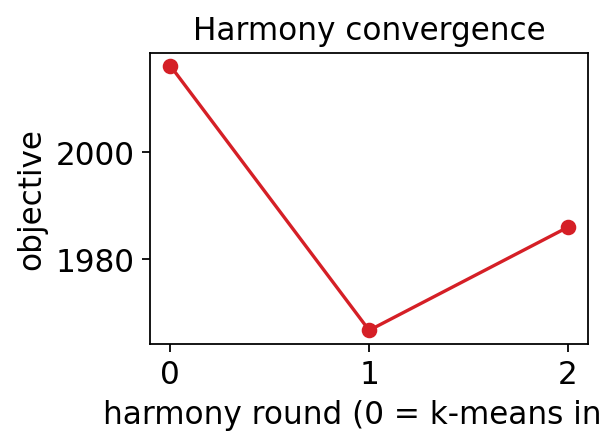

In [4]:
obj = adata.uns['harmony']['objective_harmony']
fig, ax = plt.subplots(figsize=(4, 3))
ax.plot(range(len(obj)), obj, 'o-', color='#D51F26')
ax.set_xlabel('harmony round (0 = k-means init)'); ax.set_ylabel('objective')
ax.set_title('Harmony convergence'); plt.tight_layout(); plt.show()

## UMAP before and after correction

Both UMAPs are computed with the same parameters (30 neighbours, cosine metric, `min_dist = 0.5`, as in ArchR's `addUMAP`).

In [5]:
%%time
for rep, key in [('X_iterative_lsi', 'X_umap_lsi'), ('X_harmony', 'X_umap_harmony')]:
    sc.pp.neighbors(adata, use_rep=rep, n_neighbors=30, metric='cosine', random_state=0, key_added=rep)
    epi.tl.umap(adata, min_dist=0.5, random_state=0, neighbors_key=rep)
    adata.obsm[key] = adata.obsm.pop('X_umap')

computing neighbors


    finished: added to `.uns['X_iterative_lsi']`
    `.obsp['X_iterative_lsi_distances']`, distances for each pair of neighbors
    `.obsp['X_iterative_lsi_connectivities']`, weighted adjacency matrix (0:00:28)


Computing UMAP embedding...


    Finished computing UMAP
    Added:
        'X_umap', UMAP coordinates (adata.obsm)
        'umap', UMAP parameters (adata.uns)
computing neighbors


    finished: added to `.uns['X_harmony']`
    `.obsp['X_harmony_distances']`, distances for each pair of neighbors
    `.obsp['X_harmony_connectivities']`, weighted adjacency matrix (0:00:02)


Computing UMAP embedding...


    Finished computing UMAP
    Added:
        'X_umap', UMAP coordinates (adata.obsm)
        'umap', UMAP parameters (adata.uns)
CPU times: user 52.5 s, sys: 687 ms, total: 53.1 s
Wall time: 52.1 s


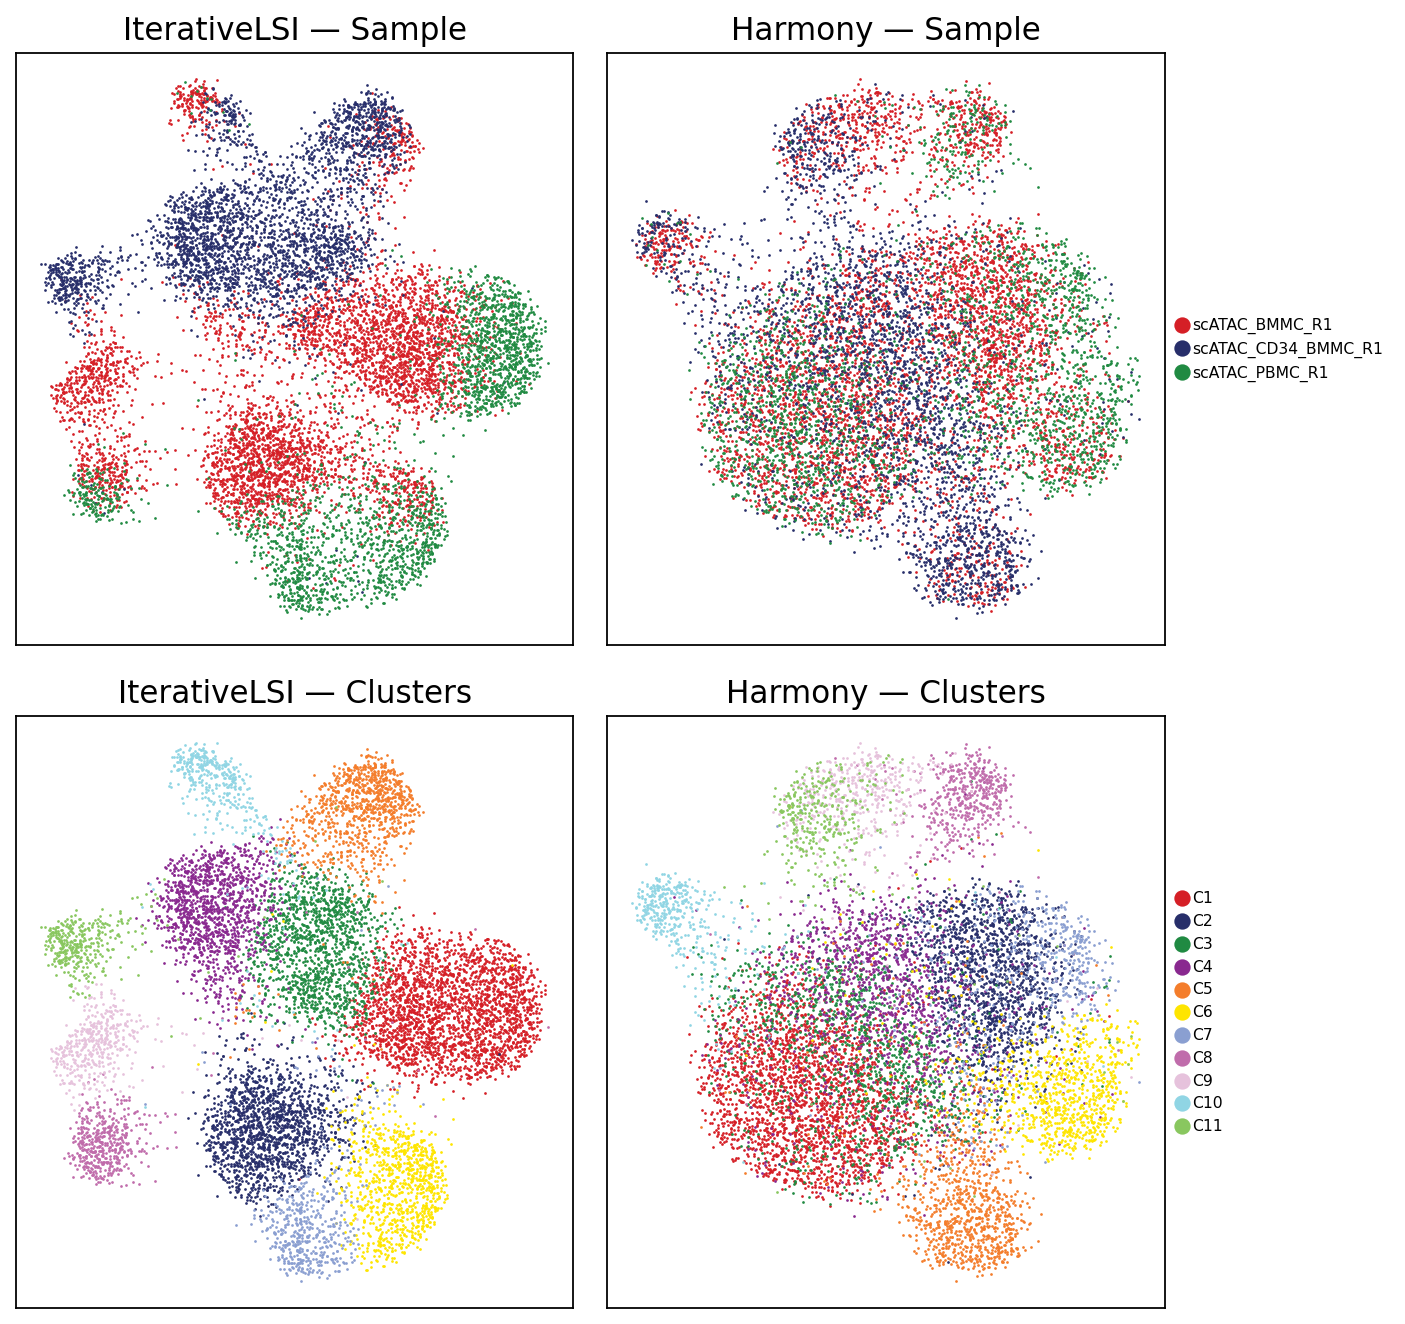

In [6]:
def archr_scatter(ax, xy, labels, title, palette):
    cats = labels.cat.categories
    for i, c in enumerate(cats):
        m = (labels == c).to_numpy()
        ax.scatter(xy[m, 0], xy[m, 1], s=1.5, color=palette[i % len(palette)], label=c, rasterized=True, linewidths=0)
    ax.set_xticks([]); ax.set_yticks([]); ax.set_title(title)

sample_pal = ['#D51F26', '#272E6A', '#208A42']
clust_pal = list(ARCHR_STALLION)
fig, axes = plt.subplots(2, 2, figsize=(9, 8.5))
for col, (key, name) in enumerate([('X_umap_lsi', 'IterativeLSI'), ('X_umap_harmony', 'Harmony')]):
    archr_scatter(axes[0, col], adata.obsm[key], adata.obs['Sample'], f'{name} — Sample', sample_pal)
    archr_scatter(axes[1, col], adata.obsm[key], adata.obs['Clusters'], f'{name} — Clusters', clust_pal)
axes[0, 1].legend(markerscale=6, fontsize=7, frameon=False, loc='center left', bbox_to_anchor=(1, 0.5))
axes[1, 1].legend(markerscale=6, fontsize=7, frameon=False, loc='center left', bbox_to_anchor=(1, 0.5), ncol=1)
plt.tight_layout(); plt.show()

### How well are the samples mixed?

For each cell we take its 30 nearest neighbours in the embedding. Sample-mixing entropy is the Shannon entropy of the neighbours' sample labels, normalised to [0, 1]. Neighbourhood cluster purity is the fraction of neighbours that share the cell's ArchR cluster. Good integration raises mixing while keeping clusters intact. Here PBMC and BMMC share cell types, while the CD34⁺ progenitors are largely sample-specific, so mixing rises only where the biology overlaps.

In [7]:
from sklearn.neighbors import NearestNeighbors

def neighbourhood_stats(E, k=30):
    nn = NearestNeighbors(n_neighbors=k + 1).fit(E).kneighbors(E, return_distance=False)[:, 1:]
    s = adata.obs['Sample'].cat.codes.to_numpy(); c = adata.obs['Clusters'].cat.codes.to_numpy()
    n_s = len(adata.obs['Sample'].cat.categories)
    counts = np.stack([(s[nn] == j).sum(1) for j in range(n_s)], 1) / k
    with np.errstate(divide='ignore', invalid='ignore'):
        ent = -np.nansum(np.where(counts > 0, counts * np.log(counts), 0), 1) / np.log(n_s)
    return ent, (c[nn] == c[:, None]).mean(1)

rows = []
for rep in ['X_iterative_lsi', 'X_harmony']:
    ent, pur = neighbourhood_stats(adata.obsm[rep])
    adata.obs[f'mix_{rep}'] = ent
    rows.append({'embedding': rep, 'sample-mixing entropy (mean)': ent.mean(), 'cluster purity (mean)': pur.mean()})
pd.DataFrame(rows).set_index('embedding').round(3)

,sample-mixing entropy (mean),cluster purity (mean)
embedding,,
X_iterative_lsi,0.538,0.671
X_harmony,0.773,0.469


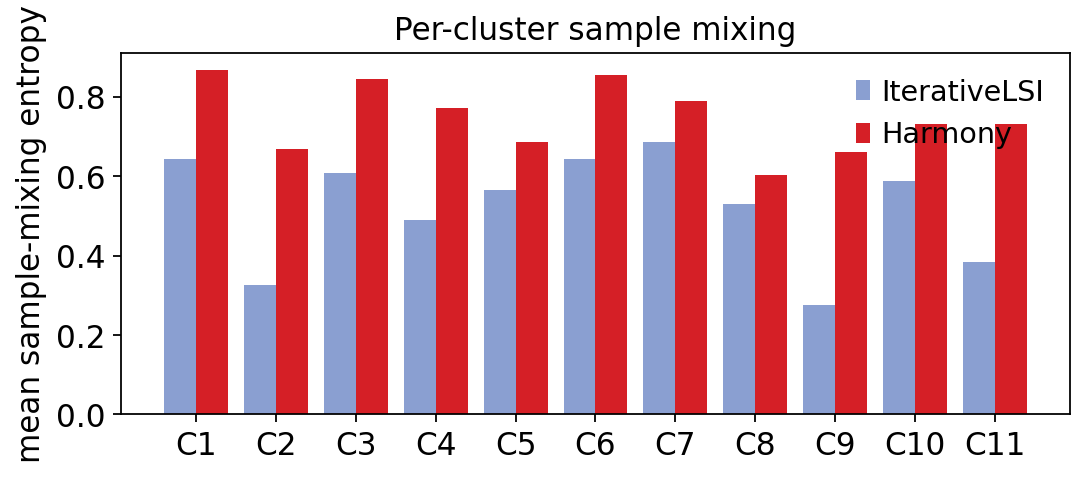

In [8]:
fig, ax = plt.subplots(figsize=(7, 3.2))
d = pd.DataFrame({'IterativeLSI': adata.obs['mix_X_iterative_lsi'], 'Harmony': adata.obs['mix_X_harmony'], 'Clusters': adata.obs['Clusters']})
m = d.groupby('Clusters', observed=True)[['IterativeLSI', 'Harmony']].mean()
x = np.arange(len(m)); w = 0.4
ax.bar(x - w/2, m['IterativeLSI'], w, label='IterativeLSI', color='#8A9FD1')
ax.bar(x + w/2, m['Harmony'], w, label='Harmony', color='#D51F26')
ax.set_xticks(x); ax.set_xticklabels(m.index, rotation=0); ax.set_ylabel('mean sample-mixing entropy')
ax.legend(frameon=False); ax.set_title('Per-cluster sample mixing'); plt.tight_layout(); plt.show()

## Parity vs ArchR

The port was validated against ArchR 1.0.3 (`set.seed(1); addHarmony(proj, reducedDims = "IterativeLSI",
groupBy = "Sample")`, harmony 1.2.4) on the same three samples, using ArchR's own iterative-LSI
embedding as input (10,660 cells × 30 dimensions). The ArchR reference outputs are generated
outside this repository. Each output had a gate fixed before the first comparison
(`tests/parity/harmony/MANIFEST.md`, omicverse-rebuildr protocol). `tests/test_harmony.py`
re-runs the check when `EPIONE_ARCHR_PARITY_DIR` points to the reference outputs.

| Output | Class | Metric | Threshold | Value |
|---|---|---|---|---|
| R RNG stream (`runif`, `sample.int`, `.Random.seed`) | deterministic-strict | exact | 0 | identical |
| `stats::kmeans` centers (`nstart = 10`) | deterministic | max abs err | 1e-8 | 8.9e-16 |
| soft assignments `R`, injected R centers + RNG state | deterministic | max abs err | 1e-8 | ≤ 5.7e-14 |
| corrected embedding per round, injected | deterministic | max abs err | 1e-8 | ≤ 4.0e-13 |
| k-means rounds / harmony rounds | exact | equality | — | [13, 9, 5] / 3, same as R |
| objective (float32) | deterministic | max rel err | 1e-6 | 1.6e-9 |
| final embedding, seed 1 / seed 42 | deterministic | max abs err | 1e-8 | 3.6e-13 / 2.6e-13 |
| final embedding | embedding | Procrustes similarity | ≥ 0.95 | 1.000000 |
| 30-nearest-neighbour graph | ranked | mean kNN Jaccard | ≥ 0.95 | 1.000000 |
| Leiden clusters | clustering | ARI | ≥ 0.95 | 1.000000 |

The remaining ~1e-13 difference comes from BLAS summation order (R uses OpenBLAS); it never
changes an assignment, a round count or the update order. Runtime on one thread: ArchR
`addHarmony` 6.2 s, `epi.tl.harmony` 2.9 s.

## Notes

* **Input.** ArchR feeds harmony `getReducedDims(proj, "IterativeLSI")`: the LSI after per-dimension scaling and removal of dimensions correlated (|r| > 0.75) with sequencing depth. To reproduce an ArchR run exactly, pass that same matrix as `use_rep`.
* **Several covariates.** Pass a list, e.g. `batch_key=['Sample', 'Donor']`. `theta` and `lambda_` then accept one value per covariate. `lambda_=None` switches on harmony's automatic λ estimation (`alpha * E`).
* **Factor levels.** Levels are taken in sorted order, as `as.factor()` does in R (or in category order for a pandas `Categorical`). Unused categories are dropped.
* **Matrix API.** `epi.tl.run_harmony(X, meta, vars_use)` mirrors `RunHarmony(data_mat, meta_data, vars_use)` and returns the corrected `cells × dims` matrix.
